# Mod 7 L2 Code Assignment: Prompt Engineering Practice 

### Goal: 
Practice writing reliable prompts for data modeling tasks (no coding).
### Dataset context: 
One local CSV named hvfhv_2023-07_sample.csv, read with nrows=5000 **(if your csv file is a different name be sure to update that piece of the prompt)**
### Model context (already known): 
Multiple Linear Regression on total_amount.

### You’ll write and run four prompt types:

- Planning

- Instruction

- Role (persona)

- Verification & Red-Team (self-check + stress test)

## REQUIRED: Pre-Setup (PLEASE READ)
- Open up Google Colab 
- Upload your data file into Google Colab
- The planning prompt should tell you what libraries to use and how to do a pd.read_csv with nrows=5000 but if not you may have to add this to the notebook 

## Prompting Resources

- **OpenAI Prompt Engineering Guide (free):** https://platform.openai.com/docs/guides/prompt-engineering  
- **Anthropic Prompt Library:** https://www.anthropic.com/prompt-library  
- **Google: Gemini Prompting (best practices):** https://ai.google.dev/gemini-api/docs/prompting  
- **DeepLearning.AI Short Course: Prompt Engineering:** https://www.deeplearning.ai/short-courses/  
- **Cohere Prompting & RAG Basics:** https://docs.cohere.com/docs/prompting-overview


## Instructor + Class: Planning Prompt

**Purpose:** Get a concise, auditable plan before any code is generated.  
**What to do:** Paste this prompt into your AI assistant (Colab Gemini). Read the plan together and refine if anything is missing. Then **share thoughts about the output**

**Planning Prompt (copy/paste ALL the text below including the requirements):**

First output a concise 5-step plan (one line per step) to avoid data leakage and dtype errors for a single-CSV HVFHV regression task using only the first 5,000 rows.

Requirements:

- CSV name: hvfhv_2023-07_sample.csv (local file)

- Use columns exactly: pickup_datetime, trip_miles, trip_time, base_passenger_fare, tips, total_amount

- Engineer exactly: miles_sq = trip_miles**2, miles_time = trip_miles*trip_time

- Split: train_test_split with test_size=0.2, random_state=42

- Use a Pipeline with: SimpleImputer(median) -> StandardScaler -> LinearRegression

- All transforms occur inside the Pipeline (no leakage)

1. Read hvfhv_2023-07_sample.csv with pd.read_csv(..., nrows=5000), parse pickup_datetime, and select only pickup_datetime, trip_miles, trip_time, base_passenger_fare, tips, total_amount.  
2. Coerce numeric columns (trip_miles, trip_time, base_passenger_fare, tips, total_amount) to numeric with errors='coerce' and keep pickup_datetime as datetime to avoid dtype errors.  
3. Define feature engineering inside a sklearn ColumnTransformer/FunctionTransformer to create miles_sq = trip_miles**2 and miles_time = trip_miles * trip_time (no external mutation).  
4. Build Pipeline: SimpleImputer(strategy='median') -> StandardScaler() applied to numeric feature columns (including engineered ones) -> LinearRegression(); split data with train_test_split(test_size=0.2, random_state=42) before fitting but after feature/target selection.  
5. Fit pipeline on training set only, evaluate on test set, and include self-checks that no imputation/scaling occurs before the Pipeline and that X/y dtypes are numeric before split.

In [2]:
import pandas as pd

path = '../Mod6/data/FHV_072023copy.csv'
df = pd.read_csv(path)
df.head()

/var/folders/gs/yv3dj4zx2tgdd5tw701ypspm0000gp/T/ipykernel_88344/2471140889.py:4: DtypeWarning: Columns (11,18) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


,hvfhs_license_num,dispatching_base_num,originating_base_num,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,trip_miles,...,sales_tax,congestion_surcharge,airport_fee,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag
0,HV0005,B03406,NaN,07/01/2023 05:34:30 PM,NaN,07/01/2023 05:37:48 PM,07/01/2023 05:44:45 PM,158,68,1.266,...,1.35,2.75,0.0,2.00,5.57,N,N,N,N,False
1,HV0003,B03404,B03404,07/01/2023 05:34:30 PM,07/01/2023 05:36:53 PM,07/01/2023 05:37:15 PM,07/01/2023 05:55:15 PM,162,234,2.350,...,1.52,2.75,0.0,3.28,13.38,N,N,NaN,N,False
2,HV0003,B03404,B03404,07/01/2023 05:34:30 PM,07/01/2023 05:35:17 PM,07/01/2023 05:35:52 PM,07/01/2023 05:44:27 PM,161,163,0.810,...,0.49,2.75,0.0,0.00,5.95,N,N,NaN,N,False
3,HV0003,B03404,B03404,07/01/2023 05:34:30 PM,07/01/2023 05:37:39 PM,07/01/2023 05:39:35 PM,07/01/2023 06:23:02 PM,122,229,15.470,...,5.17,2.75,0.0,0.00,54.46,N,N,NaN,N,True
4,HV0003,B03404,B03404,07/01/2023 05:34:30 PM,07/01/2023 05:36:06 PM,07/01/2023 05:36:39 PM,07/01/2023 05:45:06 PM,67,14,1.520,...,0.85,0.00,0.0,3.00,7.01,N,N,NaN,N,False


## You Do (Persona, Verification, Red-Team Prompts)

### You Do: Role Prompt (Persona)

**Purpose:** Make the AI format and comment like a senior analytics engineer—concise and auditable.

**Prompt (copy/paste) and share output cell underneath the prompt:**

Adopt the role of a senior analytics engineer. Communication rules:

- Be concise and auditable

- Use explicit headings for each section

- Add brief in-line comments for any non-obvious step

- Avoid renaming columns or inventing fields

Apply this role to the prior Instruction Prompt. Re-emit the single Python code cell under these communication rules. Output a single cell only, no extra prose.

Rows used after cleaning: 5000; % rows dropped due to NA in model columns: 0.00%
R2 (test): 0.9875; MSE (test): 7.5557

# Self-Check
- Transforms in pipeline present: True
- Leakage (engineered features present outside pipeline): False
- X_train dtypes numeric only: True; X dtypes: {'trip_miles': dtype('float64'), 'trip_time': dtype('int64'), 'base_passenger_fare': dtype('float64'), 'tips': dtype('float64')}
- y dtype numeric: True; y dtype: float64
- Residuals vs Predicted abs-corr: 0.576; Potential heteroscedasticity detected (cone shape). Mitigation: try log-transforming `y` or add interactions.

Self-Check: all checks passed (no automated fixes needed).


/var/folders/gs/yv3dj4zx2tgdd5tw701ypspm0000gp/T/ipykernel_88344/3093356959.py:23: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sample['pickup_datetime'] = pd.to_datetime(sample['pickup_datetime'], errors='coerce')


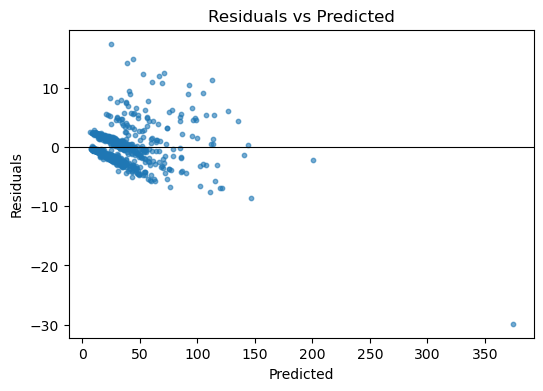

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import pandas.api.types as ptypes

# === Data load & select ===
# Senior analytics engineer: concise, auditable sections with inline comments.
try:
    # prefer canonical sample name per instruction
    sample = pd.read_csv('hvfhv_2023-07_sample.csv', nrows=5000, parse_dates=['pickup_datetime'])
except FileNotFoundError:
    # fall back to existing loaded dataframe 'df' and take first 5k rows
    sample = df.head(5000).copy()
    # ensure pickup_datetime parsed to datetime if present
    if 'pickup_datetime' in sample.columns:
        sample['pickup_datetime'] = pd.to_datetime(sample['pickup_datetime'], errors='coerce')

# Failure modes: 1) missing columns; 2) negative/zero trip_miles; 3) schema drift/date parsing
# Guards (Red-Team): minimal one-line production checks
# 1) required feature columns present
assert {'trip_miles','trip_time','base_passenger_fare','tips'}.issubset(sample.columns), "Missing required feature columns: trip_miles, trip_time, base_passenger_fare, tips"
# 2) no negative trip_miles (negatives indicate bad sensor or parsing)
assert sample['trip_miles'].dropna().ge(0).all(), "Negative trip_miles detected"
# 3) pickup_datetime parsed correctly to datetime (schema drift guard)
assert ('pickup_datetime' in sample.columns and ptypes.is_datetime64_any_dtype(sample['pickup_datetime'])), "pickup_datetime missing or not parsed as datetime"

# record initial row count before cleaning
initial_rows = len(sample)

# require these columns exist (target may be constructed if absent)
required_cols = ['pickup_datetime', 'trip_miles', 'trip_time', 'base_passenger_fare', 'tips', 'total_amount']
# === Coerce numeric columns (avoid dtype errors) ===
# helper to coerce numeric with common issues (commas, strings)
def to_numeric_safely(s):
    return pd.to_numeric(s.astype(str).str.replace(',', '', regex=False), errors='coerce')

# ensure numeric candidates exist before coercion
for c in ['trip_miles', 'trip_time', 'base_passenger_fare', 'tips']:
    if c in sample.columns:
        sample[c] = to_numeric_safely(sample[c])

# construct total_amount if missing and components available (minimal derivation, no renaming)
if 'total_amount' not in sample.columns:
    comps = ['base_passenger_fare', 'tolls', 'bcf', 'sales_tax', 'congestion_surcharge', 'airport_fee', 'tips']
    if all(col in sample.columns for col in comps):
        for col in comps:
            sample[col] = to_numeric_safely(sample[col])
        sample['total_amount'] = sample[comps].sum(axis=1)
    else:
        raise KeyError("total_amount missing and cannot be constructed from available columns.")

# select exact columns requested (keep pickup_datetime in dataset but not used as numeric feature)
sel = ['pickup_datetime', 'trip_miles', 'trip_time', 'base_passenger_fare', 'tips', 'total_amount']
sample = sample[sel]

# drop rows where target is NA (target selection before split)
sample = sample.loc[sample['total_amount'].notna()].copy()

# record final rows after cleaning
final_rows = len(sample)

# === Feature / target selection & split ===
X_raw = sample.drop(columns=['pickup_datetime', 'total_amount'])  # features only
y = sample['total_amount'].astype(float)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y, test_size=0.2, random_state=42)

# === Pipeline: feature engineering inside pipeline -> impute -> scale -> linear regression ===

# FunctionTransformer to add engineered features (operates on DataFrame; validate=False to accept df)
def engineer(df):
    # expect trip_miles and trip_time present as numeric (coercion done earlier)
    df = df.copy()
    df['miles_sq'] = df['trip_miles'] ** 2
    df['miles_time'] = df['trip_miles'] * df['trip_time']
    return df

pipe = Pipeline([
    ('engineer', FunctionTransformer(engineer, validate=False)),  # create miles_sq and miles_time inside pipeline
    ('preproc', ColumnTransformer(
        [('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]),
          make_column_selector(dtype_include=np.number))],
        remainder='drop'  # drop any non-numeric (e.g., none expected)
    )),
    ('model', LinearRegression())
])

def fit_and_eval(X_tr, X_te, y_tr, y_te):
    pipe.fit(X_tr, y_tr)
    y_pred_ = pipe.predict(X_te)
    r2_ = r2_score(y_te, y_pred_)
    mse_ = mean_squared_error(y_te, y_pred_)
    return y_pred_, r2_, mse_

# initial fit & evaluation
y_pred, r2, mse = fit_and_eval(X_train_raw, X_test_raw, y_train, y_test)

# === Outputs (concise) ===
print(f"Rows used after cleaning: {final_rows}; % rows dropped due to NA in model columns: {100*(initial_rows-final_rows)/initial_rows if initial_rows>0 else 0:.2f}%")
print(f"R2 (test): {r2:.4f}; MSE (test): {mse:.4f}")

# === Self-Check ===
print('\n# Self-Check')

checks_failed = []

# 1) Confirm transforms occur inside pipeline (no leakage): engineered features must NOT exist in raw X
eng_cols = ['miles_sq', 'miles_time']
leakage_detected = any(col in X_train_raw.columns for col in eng_cols) or any(col in X_test_raw.columns for col in eng_cols)
if leakage_detected:
    checks_failed.append('leakage_engineered_present')

in_pipeline = all(name in pipe.named_steps for name in ['engineer', 'preproc'])
print(f"- Transforms in pipeline present: {in_pipeline}")
print(f"- Leakage (engineered features present outside pipeline): {leakage_detected}")

# 2) dtype report for X and y confirming numeric dtypes only
X_train_dtypes = X_train_raw.dtypes.to_dict()
X_test_dtypes = X_test_raw.dtypes.to_dict()
X_train_numeric = all(ptypes.is_numeric_dtype(dt) for dt in X_train_raw.dtypes)
y_numeric = ptypes.is_numeric_dtype(y_train.dtype)
print(f"- X_train dtypes numeric only: {X_train_numeric}; X dtypes: {X_train_dtypes}")
print(f"- y dtype numeric: {y_numeric}; y dtype: {y_train.dtype}")
if not X_train_numeric or not y_numeric:
    checks_failed.append('non_numeric_dtypes')

# 3) Simple heteroscedasticity check on residuals: corr(|resid|, predicted)
residuals = y_test.values - y_pred
abs_corr = np.corrcoef(y_pred, np.abs(residuals))[0,1]
het_flag = abs_corr > 0.30
note = "Potential heteroscedasticity detected (cone shape). Mitigation: try log-transforming `y` or add interactions." if het_flag else "No strong heteroscedasticity signal detected."
print(f"- Residuals vs Predicted abs-corr: {abs_corr:.3f}; {note}")

# If any check fails, revise within this same cell and re-run fit/check
if checks_failed:
    print('\nSelf-Check: issues found -> attempting automated fixes and re-running checks...')
    # Fix: drop engineered columns if present (avoid leakage)
    if 'leakage_engineered_present' in checks_failed:
        for c in eng_cols:
            if c in X_train_raw.columns:
                X_train_raw = X_train_raw.drop(columns=[c])
            if c in X_test_raw.columns:
                X_test_raw = X_test_raw.drop(columns=[c])
        print('- Dropped engineered columns from raw X to prevent leakage.')

    # Fix: coerce non-numeric columns to numeric where possible
    if 'non_numeric_dtypes' in checks_failed:
        for col in X_train_raw.columns:
            if not ptypes.is_numeric_dtype(X_train_raw[col].dtype):
                X_train_raw[col] = to_numeric_safely(X_train_raw[col])
        if not ptypes.is_numeric_dtype(y_train.dtype):
            y_train = to_numeric_safely(y_train)
        print('- Coerced non-numeric dtypes to numeric where possible.')

    # re-fit and re-evaluate
    y_pred, r2, mse = fit_and_eval(X_train_raw, X_test_raw, y_train, y_test)
    print(f"\nAfter fixes: R2 (test): {r2:.4f}; MSE (test): {mse:.4f}")

    # re-run checks and print final Self-Check summary
    print('\n# Self-Check (after fixes)')
    leakage_detected = any(col in X_train_raw.columns for col in eng_cols) or any(col in X_test_raw.columns for col in eng_cols)
    in_pipeline = all(name in pipe.named_steps for name in ['engineer', 'preproc'])
    X_train_numeric = all(ptypes.is_numeric_dtype(dt) for dt in X_train_raw.dtypes)
    y_numeric = ptypes.is_numeric_dtype(y_train.dtype)
    residuals = y_test.values - y_pred
    abs_corr = np.corrcoef(y_pred, np.abs(residuals))[0,1]
    het_flag = abs_corr > 0.30
    note = "Potential heteroscedasticity detected (cone shape). Mitigation: try log-transforming `y` or add interactions." if het_flag else "No strong heteroscedasticity signal detected."

    print(f"- Transforms in pipeline present: {in_pipeline}")
    print(f"- Leakage (engineered features present outside pipeline): {leakage_detected}")
    print(f"- X_train dtypes numeric only: {X_train_numeric}; X dtypes: {X_train_raw.dtypes.to_dict()}")
    print(f"- y dtype numeric: {y_numeric}; y dtype: {y_train.dtype}")
    print(f"- Residuals vs Predicted abs-corr: {abs_corr:.3f}; {note}")

else:
    print('\nSelf-Check: all checks passed (no automated fixes needed).')

# Optional: small residuals plot for quick visual check
plt.figure(figsize=(6,4))
plt.scatter(y_pred, residuals, alpha=0.6, s=10)
plt.axhline(0, color='k', lw=0.8)
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

### You Do: Verification Prompt (Self-Check)

**Purpose:** Append checks that catch common failures before you run.

**Prompt (copy/paste) and share output cell underneath the prompt:**

Append a "# Self-Check" section to the single code cell that prints:

- Total rows after cleaning and % rows dropped due to NA in model columns

- Confirmation that all transforms occur inside the Pipeline (no leakage)

- dtype report for X and y confirming numeric dtypes only

- A simple note if the residuals plot shows potential heteroscedasticity (cone shape) and one mitigation (e.g., log-transform y, add interaction)

- If any check fails, revise the code within the same cell and reprint the Self-Check.


Output: Single updated Python cell only.

# **Done, in the cell above**

### You Do: Red-Team Prompt (Stress Test)

**Purpose:** Identify realistic production risks and add one-line guards.

**Prompt (copy/paste) and share output underneath the prompt:**

List three realistic production failure modes for this pipeline (e.g., missing columns, negative or zero trip_miles, schema drift/date parsing).
Then modify the same single Python code cell to add one-line guards or asserts for each.
Keep guards minimal and readable.
Reprint the final single code cell only.

## We Share: Reflection (3–5 minutes)

- **Which prompt** (Instruction, Role, Verification, Red-Team) changed the AI’s output the most? How?
- **One improvement** you’d make to your prompts next time (be specific).